# Integrated regulation

Synthesize gene-level and pathway-level signals across the sequenced RNA pools.


In [1]:
from pathlib import Path

import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

ALPHA = 0.05
REDUNDANCY_THRESHOLD = 0.5
REDUNDANCY_THRESHOLDS = (0.3, 0.5, 0.7)
MAX_MODULE_GENES = 12
ASD_CORRELATION_PERMUTATIONS = 10_000
RANDOM_SEED = 1077
ANALYSES = {
    'input': 'inputDifferentialExpression.tsv',
    'monosome': 'monosomeDifferentialAbundance.tsv',
    'polysome': 'polysomeDifferentialAbundance.tsv',
    'redistribution': 'polysomeMonosome.tsv',
}
ANALYSIS_LABELS = {
    'input': 'Input RNA',
    'monosome': 'Monosome-associated RNA',
    'polysome': 'Polysome-associated RNA',
    'redistribution': 'Polysome–monosome redistribution',
}
SHORT_ANALYSIS_LABELS = {
    'input': 'Input',
    'monosome': 'Monosome',
    'polysome': 'Polysome',
    'redistribution': 'Redistribution',
}
COLLECTION_LABELS = {
    'goBiologicalProcess': 'GO BP',
    'goCellularComponent': 'GO CC',
    'goMolecularFunction': 'GO MF',
    'synGO': 'SynGO',
    'fuAsd': 'Fu ASD',
}
METRICS = (
    'baseMean',
    'log2FoldChange',
    'log2FoldChangeSE',
    'statistic',
    'pValue',
    'adjustedPValue',
)

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load the complete gene-level and enrichment results.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
GENE_SET_DIR = DATA_DIR / 'geneSets'
RESULTS_DIR = ROOT / 'results'

gene_tables = {
    analysis: pd.read_csv(RESULTS_DIR / filename, sep = '\t')
    for analysis, filename in ANALYSES.items()
}
ranked = pd.read_csv(RESULTS_DIR / 'rankedEnrichment.tsv', sep = '\t')
ora = pd.read_csv(RESULTS_DIR / 'overrepresentationAnalysis.tsv', sep = '\t')
manifest = pd.read_csv(GENE_SET_DIR / 'geneSetManifest.tsv', sep = '\t')

required_gene_columns = {'geneId', 'geneName', *METRICS}

for analysis, table in gene_tables.items():
    missing = required_gene_columns.difference(table.columns)
    if missing:
        raise ValueError(f'{analysis} results are missing: {sorted(missing)}')
    if table['geneId'].isna().any() or not table['geneId'].is_unique:
        raise ValueError(f'{analysis} gene identifiers must be complete and unique.')

required_ranked_columns = {
    'analysis',
    'collection',
    'term',
    'direction',
    'normalizedEnrichmentScore',
    'pValue',
    'adjustedPValue',
    'leadingEdgeGenesCount',
    'leadingEdgeGenes',
}
if required_ranked_columns.difference(ranked.columns):
    raise ValueError('Ranked enrichment results are incomplete.')
if set(ranked['analysis']) != set(ANALYSES):
    raise ValueError('Ranked enrichment analyses are incomplete.')
if set(ranked['collection']) != set(COLLECTION_LABELS):
    raise ValueError('Ranked enrichment collections are incomplete.')

gene_sets = {}

for row in manifest.itertuples(index = False):
    path = GENE_SET_DIR / row.fileName
    terms = gp.read_gmt(str(path))
    terms = {
        str(term): {str(gene).upper() for gene in genes}
        for term, genes in terms.items()
    }
    if len(terms) != row.terms:
        raise ValueError(f'Term count does not match the manifest: {path.name}')
    gene_sets[row.collection] = terms

display(manifest)


,collection,fileName,sourceLibrary,sourceTerms,terms,retrievedDate,sourceUrl
0,goBiologicalProcess,goBiologicalProcess2026.gmt,GO_Biological_Process_2026,all,5952,2026-08-27,https://maayanlab.cloud/Enrichr/
1,goCellularComponent,goCellularComponent2026.gmt,GO_Cellular_Component_2026,all,506,2026-08-27,https://maayanlab.cloud/Enrichr/
2,goMolecularFunction,goMolecularFunction2026.gmt,GO_Molecular_Function_2026,all,1394,2026-08-27,https://maayanlab.cloud/Enrichr/
3,synGO,synGO2024.gmt,SynGO_2024,all,134,2026-08-27,https://maayanlab.cloud/Enrichr/
4,fuAsd,fuAsd2022.gmt,Fu et al. 2022 Supplementary Table 11,ASD72;ASD185,2,2026-09-04,https://doi.org/10.1038/s41588-022-01104-0


In [3]:
# Merge the tested gene universes without converting missing tests to null effects.


def prefix_metrics(table: pd.DataFrame, analysis: str):
    renamed = table.set_index('geneId').loc[:, METRICS].copy()
    renamed.columns = [
        f'{analysis}{column[0].upper()}{column[1:]}'
        for column in renamed.columns
    ]
    return renamed


annotations = pd.concat([
    table[['geneId', 'geneName']].assign(analysis = analysis)
    for analysis, table in gene_tables.items()
], ignore_index = True)
annotation_conflicts = annotations.dropna(subset = ['geneName']).groupby('geneId')[
    'geneName'
].nunique()

if annotation_conflicts.gt(1).any():
    raise ValueError('Gene names disagree across gene-level result tables.')

gene_names = annotations.drop_duplicates('geneId').set_index('geneId')['geneName']
gene_index = pd.Index(
    sorted(set().union(*(table['geneId'] for table in gene_tables.values()))),
    name = 'geneId',
)
integrated = gene_names.reindex(gene_index).to_frame()

for analysis, table in gene_tables.items():
    integrated = integrated.join(prefix_metrics(table, analysis), how = 'left')

fdr_columns = []

for analysis in ANALYSES:
    column = f'{analysis}Fdr'
    adjusted = f'{analysis}AdjustedPValue'
    integrated[column] = integrated[adjusted].lt(ALPHA)
    fdr_columns.append(column)

integrated['fdrLayerCount'] = integrated[fdr_columns].sum(axis = 1)
integrated['fdrLayers'] = integrated[fdr_columns].apply(
    lambda row: ';'.join(
        analysis
        for analysis, column in zip(ANALYSES, fdr_columns)
        if row[column]
    ),
    axis = 1,
)

comparison = pd.read_csv(
    RESULTS_DIR / 'fractionRedistributionComparison.tsv',
    sep = '\t',
).set_index('geneId')
decomposition_columns = [
    'polysomeInputLog2FoldChange',
    'polysomeInputLog2FoldChangeSE',
    'polysomeInputStatistic',
    'polysomeInputPValue',
    'polysomeInputAdjustedPValue',
    'monosomeInputLog2FoldChange',
    'monosomeInputLog2FoldChangeSE',
    'monosomeInputStatistic',
    'monosomeInputPValue',
    'monosomeInputAdjustedPValue',
    'independentFractionLog2FoldChangeDifference',
]

if set(decomposition_columns).difference(comparison.columns):
    raise ValueError('The redistribution decomposition is incomplete.')

integrated = integrated.join(comparison[decomposition_columns], how = 'left')
theta_pm = comparison['polysomeMonosomeLog2FoldChange']
theta_pi = comparison['polysomeInputLog2FoldChange']
theta_mi = comparison['monosomeInputLog2FoldChange']
algebra_error = theta_pm - (theta_pi - theta_mi)
independent_delta = (
    integrated['polysomeLog2FoldChange']
    - integrated['monosomeLog2FoldChange']
)
independent_error = (
    independent_delta
    - integrated['independentFractionLog2FoldChangeDifference']
)

if not np.allclose(algebra_error, 0, rtol = 1e-10, atol = 1e-10):
    raise ValueError('The Monopoly contrast decomposition is inconsistent.')
if not np.allclose(
    independent_error.dropna(),
    0,
    rtol = 1e-10,
    atol = 1e-10,
):
    raise ValueError('The separate-model effect difference is inconsistent.')

integration_summary = pd.DataFrame([
    {
        'analysis': analysis,
        'testedGenes': len(table),
        'fdrGenes': int(table['adjustedPValue'].lt(ALPHA).sum()),
    }
    for analysis, table in gene_tables.items()
])
algebra_summary = pd.DataFrame({
    'comparison': ['Monopoly decomposition', 'Separate-model difference'],
    'genesCompared': [
        int(algebra_error.notna().sum()),
        int(independent_error.notna().sum()),
    ],
    'maximumAbsoluteError': [
        algebra_error.abs().max(),
        independent_error.abs().max(),
    ],
})

display(integration_summary)
display(algebra_summary)


,analysis,testedGenes,fdrGenes
0,input,21556,305
1,monosome,21888,192
2,polysome,21256,204
3,redistribution,20470,22


,comparison,genesCompared,maximumAbsoluteError
0,Monopoly decomposition,20470,3.552714e-15
1,Separate-model difference,20470,1.776357e-15


In [4]:
# Collapse duplicate symbols exactly as in the ranked enrichment workflow.


def collapse_symbols(table: pd.DataFrame):
    mapped = table.copy()
    mapped['geneSymbol'] = (
        mapped['geneName'].astype('string').str.strip().str.upper()
    )
    valid = (
        mapped['geneSymbol'].notna()
        & mapped['geneSymbol'].ne('')
        & ~mapped['geneSymbol'].str.startswith('ENSG')
        & np.isfinite(mapped['statistic'])
        & np.isfinite(mapped['baseMean'])
    )
    mapped = mapped.loc[valid].sort_values(
        ['baseMean', 'geneId'],
        ascending = [False, True],
    )
    return mapped.drop_duplicates('geneSymbol').set_index(
        'geneSymbol',
        drop = False,
    )


symbol_tables = {
    analysis: collapse_symbols(table)
    for analysis, table in gene_tables.items()
}
symbol_index = pd.Index(
    sorted(set().union(*(table.index for table in symbol_tables.values()))),
    name = 'geneSymbol',
)
symbol_results = pd.DataFrame(index = symbol_index)

for analysis, table in symbol_tables.items():
    for metric in METRICS:
        name = f'{analysis}{metric[0].upper()}{metric[1:]}'
        symbol_results[name] = table[metric].reindex(symbol_index)


In [5]:
# Quantify genome-wide agreement among the four signed Wald-statistic layers.
# Redistribution correlations are descriptive because the contrast contains both pools.

statistic_columns = [
    f'{analysis}Statistic'
    for analysis in ANALYSES
]
statistic_matrix = symbol_results[statistic_columns].rename(columns = {
    f'{analysis}Statistic': analysis
    for analysis in ANALYSES
})
correlation_records = []

for x_analysis in ANALYSES:
    for y_analysis in ANALYSES:
        complete = pd.concat({
            'x': statistic_matrix[x_analysis],
            'y': statistic_matrix[y_analysis],
        }, axis = 1).dropna()
        result = spearmanr(
            complete['x'],
            complete['y'],
        )
        correlation_records.append({
            'xAnalysis': x_analysis,
            'yAnalysis': y_analysis,
            'genes': len(complete),
            'spearmanRho': result.statistic,
            'pValue': result.pvalue,
        })

layer_correlation = pd.DataFrame(correlation_records)
correlation_matrix = layer_correlation.pivot(
    index = 'yAnalysis',
    columns = 'xAnalysis',
    values = 'spearmanRho',
).reindex(index = ANALYSES, columns = ANALYSES)

if not np.allclose(correlation_matrix, correlation_matrix.T):
    raise ValueError('The layer-correlation matrix is not symmetric.')

display(layer_correlation)


,xAnalysis,yAnalysis,genes,spearmanRho,pValue
0,input,input,17762,1.000000,0.000000e+00
1,input,monosome,17186,0.512600,0.000000e+00
2,input,polysome,17228,0.589975,0.000000e+00
3,input,redistribution,16965,0.064184,5.861917e-17
4,monosome,input,17186,0.512600,0.000000e+00
5,monosome,monosome,17741,1.000000,0.000000e+00
6,monosome,polysome,17160,0.423877,0.000000e+00
7,monosome,redistribution,17160,-0.483792,0.000000e+00
8,polysome,input,17228,0.589975,0.000000e+00
9,polysome,monosome,17160,0.423877,0.000000e+00


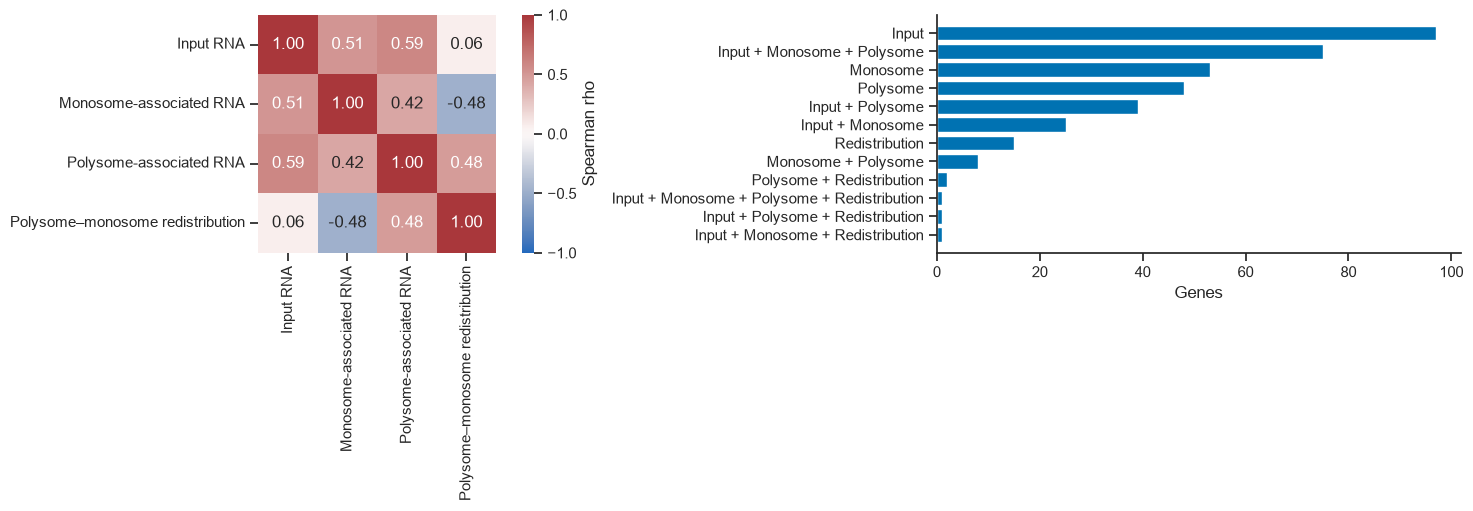

,input,monosome,polysome,redistribution,genes,universeGenes,signature
0,True,False,False,False,97,16965,Input
1,True,True,True,False,75,16965,Input + Monosome + Polysome
2,False,True,False,False,53,16965,Monosome
3,False,False,True,False,48,16965,Polysome
4,True,False,True,False,39,16965,Input + Polysome
5,True,True,False,False,25,16965,Input + Monosome
6,False,False,False,True,15,16965,Redistribution
7,False,True,True,False,8,16965,Monosome + Polysome
8,False,False,True,True,2,16965,Polysome + Redistribution
11,True,True,True,True,1,16965,Input + Monosome + Polysome + Redistribution


In [6]:
# Summarize FDR-set overlap among genes tested in all four layers.

common_symbols = pd.Index(
    sorted(set.intersection(*(set(table.index) for table in symbol_tables.values()))),
    name = 'geneSymbol',
)
fdr_matrix = pd.DataFrame(index = common_symbols)

for analysis in ANALYSES:
    adjusted = symbol_results.loc[
        common_symbols,
        f'{analysis}AdjustedPValue',
    ]
    fdr_matrix[analysis] = adjusted.lt(ALPHA)

selected = fdr_matrix.loc[fdr_matrix.any(axis = 1)]
fdr_overlap = selected.value_counts().rename('genes').reset_index()
fdr_overlap['universeGenes'] = len(common_symbols)
fdr_overlap['signature'] = fdr_overlap.apply(
    lambda row: ' + '.join(
        SHORT_ANALYSIS_LABELS[analysis]
        for analysis in ANALYSES
        if row[analysis]
    ),
    axis = 1,
)
fdr_overlap = fdr_overlap.sort_values(
    ['genes', 'signature'],
    ascending = [False, True],
)

figure, axes = plt.subplots(1, 2, figsize = (15, 5), constrained_layout = True)
sns.heatmap(
    correlation_matrix.rename(
        index = ANALYSIS_LABELS,
        columns = ANALYSIS_LABELS,
    ),
    annot = True,
    fmt = '.2f',
    vmin = -1,
    vmax = 1,
    center = 0,
    cmap = 'vlag',
    square = True,
    cbar_kws = {'label': 'Spearman rho'},
    ax = axes[0],
)
axes[0].set(xlabel = '', ylabel = '')

plot_overlap = fdr_overlap.head(12).sort_values('genes')
axes[1].barh(plot_overlap['signature'], plot_overlap['genes'], color = '#0072B2')
axes[1].set(xlabel = 'Genes', ylabel = '')
sns.despine(ax = axes[1])
plt.show()

display(fdr_overlap)


In [7]:
# Integrate ranked pathway results.
# Retain unavailable tests instead of replacing them with null effects.

pathway_metrics = (
    'direction',
    'normalizedEnrichmentScore',
    'pValue',
    'adjustedPValue',
    'leadingEdgeGenesCount',
    'leadingEdgeGenes',
)
pathway_index = pd.MultiIndex.from_frame(
    ranked[['collection', 'term']].drop_duplicates().sort_values(
        ['collection', 'term']
    )
)
integrated_pathways = pd.DataFrame(index = pathway_index)

for analysis in ANALYSES:
    table = ranked.loc[ranked['analysis'].eq(analysis)].set_index(
        ['collection', 'term']
    )
    if not table.index.is_unique:
        raise ValueError(f'{analysis} ranked pathway results must be unique.')
    for metric in pathway_metrics:
        name = f'{analysis}{metric[0].upper()}{metric[1:]}'
        integrated_pathways[name] = table[metric].reindex(pathway_index)

pathway_fdr_columns = []

for analysis in ANALYSES:
    column = f'{analysis}Fdr'
    adjusted = f'{analysis}AdjustedPValue'
    integrated_pathways[column] = integrated_pathways[adjusted].lt(ALPHA)
    pathway_fdr_columns.append(column)

integrated_pathways['fdrLayerCount'] = integrated_pathways[
    pathway_fdr_columns
].sum(axis = 1)
integrated_pathways['fdrLayers'] = integrated_pathways[
    pathway_fdr_columns
].apply(
    lambda row: ';'.join(
        analysis
        for analysis, column in zip(ANALYSES, pathway_fdr_columns)
        if row[column]
    ),
    axis = 1,
)
shared_pathways = integrated_pathways.loc[
    integrated_pathways['fdrLayerCount'].ge(2)
].reset_index().sort_values(
    ['fdrLayerCount', 'collection', 'term'],
    ascending = [False, True, True],
)

display(shared_pathways[[
    'collection',
    'term',
    'fdrLayerCount',
    'fdrLayers',
]])


,collection,term,fdrLayerCount,fdrLayers
40,goCellularComponent,U2-type Spliceosomal Complex (GO:0005684),3,monosome;polysome;redistribution
0,fuAsd,Fu ASD FDR <= 0.001,2,monosome;redistribution
1,fuAsd,Fu ASD FDR <= 0.05,2,monosome;redistribution
2,goBiologicalProcess,ADP Catabolic Process (GO:0046032),2,monosome;polysome
3,goBiologicalProcess,ATP Metabolic Process (GO:0046034),2,monosome;polysome
4,goBiologicalProcess,Antibacterial Humoral Response (GO:0019731),2,polysome;redistribution
5,goBiologicalProcess,Aorta Development (GO:0035904),2,polysome;redistribution
6,goBiologicalProcess,Autonomic Nervous System Development (GO:0048483),2,monosome;polysome
7,goBiologicalProcess,Canonical Glycolysis (GO:0061621),2,monosome;polysome
8,goBiologicalProcess,Carbohydrate Catabolic Process (GO:0016052),2,monosome;polysome


In [8]:
# Expand significant leading edges and quantify recurrent gene drivers.

ranked_fdr = ranked.loc[ranked['adjustedPValue'].lt(ALPHA)].copy()
leading_records = []

for row in ranked_fdr.itertuples(index = False):
    genes = row.leadingEdgeGenes.split(';')
    if len(genes) != row.leadingEdgeGenesCount:
        raise ValueError(f'Leading-edge count is inconsistent for {row.term}.')
    for gene in genes:
        leading_records.append({
            'analysis': row.analysis,
            'collection': row.collection,
            'direction': row.direction,
            'term': row.term,
            'geneSymbol': gene,
            'adjustedPValue': row.adjustedPValue,
            'normalizedEnrichmentScore': row.normalizedEnrichmentScore,
        })

leading_edges = pd.DataFrame(leading_records)
leading_edge_summary = leading_edges.groupby(
    ['analysis', 'collection', 'direction', 'geneSymbol'],
    observed = True,
).agg(
    termOccurrences = ('term', 'nunique'),
    bestAdjustedPValue = ('adjustedPValue', 'min'),
    maximumAbsoluteNormalizedEnrichmentScore = (
        'normalizedEnrichmentScore',
        lambda values: values.abs().max(),
    ),
    terms = ('term', lambda values: ';'.join(sorted(set(values)))),
).reset_index()

driver_summary = leading_edge_summary.sort_values(
    ['analysis', 'collection', 'direction', 'termOccurrences', 'geneSymbol'],
    ascending = [True, True, True, False, True],
).groupby(
    ['analysis', 'collection', 'direction'],
    observed = True,
).head(10)
display(driver_summary)


,analysis,collection,direction,geneSymbol,termOccurrences,bestAdjustedPValue,maximumAbsoluteNormalizedEnrichmentScore,terms
0,input,goMolecularFunction,negative,BIVM,1,0.013015,2.087275,Single-stranded DNA Binding (GO:0003697)
1,input,goMolecularFunction,negative,BLM,1,0.013015,2.087275,Single-stranded DNA Binding (GO:0003697)
2,input,goMolecularFunction,negative,BRCA2,1,0.013015,2.087275,Single-stranded DNA Binding (GO:0003697)
3,input,goMolecularFunction,negative,CDC45,1,0.013015,2.087275,Single-stranded DNA Binding (GO:0003697)
4,input,goMolecularFunction,negative,CRY2,1,0.013015,2.087275,Single-stranded DNA Binding (GO:0003697)
...,...,...,...,...,...,...,...,...
3712,redistribution,synGO,positive,ATP6V0C,1,0.001046,2.127480,Integral Component Of Synaptic Vesicle Membran...
3713,redistribution,synGO,positive,ATP6V0D1,1,0.001046,2.127480,Integral Component Of Synaptic Vesicle Membran...
3714,redistribution,synGO,positive,CLCN3,1,0.001046,2.127480,Integral Component Of Synaptic Vesicle Membran...
3715,redistribution,synGO,positive,CLTA,1,0.022666,1.856600,Synaptic Vesicle Membrane (GO:0030672) CC


In [9]:
# Reduce display redundancy using leading-edge overlap without changing inference.


def overlap_coefficient(x: set[str], y: set[str]) -> float:
    return len(x.intersection(y)) / min(len(x), len(y))


def collapse_redundancy(table: pd.DataFrame, threshold: float):
    records = []
    groups = table.groupby(
        ['analysis', 'collection', 'direction'],
        observed = True,
        sort = False,
    )

    for (analysis, collection, direction), group in groups:
        group = group.sort_values(
            ['adjustedPValue', 'pValue', 'term'],
        )
        selected_terms = []
        selected_genes = []

        for row in group.itertuples(index = False):
            genes = set(row.leadingEdgeGenes.split(';'))
            representative = row.term
            similarity = 1.0
            redundant = False

            if collection.startswith('go') and selected_terms:
                similarities = [
                    overlap_coefficient(genes, selected)
                    for selected in selected_genes
                ]
                best = int(np.argmax(similarities))
                if similarities[best] >= threshold:
                    representative = selected_terms[best]
                    similarity = similarities[best]
                    redundant = True

            if not redundant:
                selected_terms.append(row.term)
                selected_genes.append(genes)

            records.append({
                'analysis': analysis,
                'collection': collection,
                'direction': direction,
                'term': row.term,
                'representativeTerm': representative,
                'overlapCoefficient': similarity,
                'redundant': redundant,
                'threshold': threshold,
            })

    return pd.DataFrame(records)


redundancy_map = collapse_redundancy(
    ranked_fdr,
    REDUNDANCY_THRESHOLD,
)
redundancy_tables = []

for threshold in REDUNDANCY_THRESHOLDS:
    table = collapse_redundancy(ranked_fdr, threshold)
    summary = table.groupby(
        ['analysis', 'collection', 'direction'],
        observed = True,
    ).agg(
        significantTerms = ('term', 'size'),
        representativeTerms = ('representativeTerm', 'nunique'),
    ).reset_index()
    summary['threshold'] = threshold
    redundancy_tables.append(summary)

redundancy_sensitivity = pd.concat(redundancy_tables, ignore_index = True)

if len(redundancy_map) != len(ranked_fdr):
    raise ValueError('Each significant term must have one redundancy assignment.')
if redundancy_map.duplicated(
    ['analysis', 'collection', 'direction', 'term']
).any():
    raise ValueError('Redundancy assignments must be unique.')


display(redundancy_sensitivity)


,analysis,collection,direction,significantTerms,representativeTerms,threshold
0,input,goMolecularFunction,negative,1,1,0.3
1,monosome,fuAsd,positive,2,2,0.3
2,monosome,goBiologicalProcess,negative,44,19,0.3
3,monosome,goBiologicalProcess,positive,2,1,0.3
4,monosome,goCellularComponent,negative,15,7,0.3
...,...,...,...,...,...,...
64,redistribution,goCellularComponent,positive,5,4,0.7
65,redistribution,goMolecularFunction,negative,7,6,0.7
66,redistribution,goMolecularFunction,positive,10,7,0.7
67,redistribution,synGO,negative,4,4,0.7


In [10]:
# Determine whether significant SynGO translation terms are generic ribosome sets.

generic_ribosome_terms = {
    'Cytosolic Large Ribosomal Subunit (GO:0022625)',
    'Cytosolic Small Ribosomal Subunit (GO:0022627)',
    'Large Ribosomal Subunit (GO:0015934)',
    'Small Ribosomal Subunit (GO:0015935)',
}
missing_ribosome_terms = generic_ribosome_terms.difference(
    gene_sets['goCellularComponent']
)

if missing_ribosome_terms:
    raise ValueError(f'Generic ribosome terms are missing: {missing_ribosome_terms}')

generic_ribosome_genes = set().union(*(
    gene_sets['goCellularComponent'][term]
    for term in generic_ribosome_terms
))
syn_go_ribosome = ranked_fdr.loc[
    ranked_fdr['collection'].eq('synGO')
    & ranked_fdr['term'].str.contains('Ribosome|Translation At', regex = True)
]
ribosome_records = []

for row in syn_go_ribosome.itertuples(index = False):
    members = gene_sets['synGO'][row.term]
    leading = set(row.leadingEdgeGenes.split(';'))
    set_generic = members.intersection(generic_ribosome_genes)
    leading_generic = leading.intersection(generic_ribosome_genes)
    ribosome_records.append({
        'analysis': row.analysis,
        'term': row.term,
        'direction': row.direction,
        'adjustedPValue': row.adjustedPValue,
        'geneSetGenes': len(members),
        'genericRibosomeSetGenes': len(set_generic),
        'genericRibosomeSetFraction': len(set_generic) / len(members),
        'leadingEdgeGenes': len(leading),
        'genericRibosomeLeadingEdgeGenes': len(leading_generic),
        'genericRibosomeLeadingEdgeFraction': (
            len(leading_generic) / len(leading)
        ),
        'nonGenericLeadingEdgeGenes': ';'.join(
            sorted(leading.difference(generic_ribosome_genes))
        ),
    })

syn_go_ribosome_audit = pd.DataFrame(ribosome_records)
display(syn_go_ribosome_audit)


,analysis,term,direction,adjustedPValue,geneSetGenes,genericRibosomeSetGenes,genericRibosomeSetFraction,leadingEdgeGenes,genericRibosomeLeadingEdgeGenes,genericRibosomeLeadingEdgeFraction,nonGenericLeadingEdgeGenes
0,polysome,Postsynaptic Ribosome CC,negative,0.048450,69,68,0.985507,51,51,1.00000,
1,redistribution,Postsynaptic Ribosome CC,negative,0.001861,69,68,0.985507,44,44,1.00000,
2,redistribution,Presynaptic Ribosome CC,negative,0.003723,51,50,0.980392,32,32,1.00000,
3,redistribution,Translation At Presynapse (GO:0140236) BP,negative,0.003955,50,49,0.980000,31,31,1.00000,
4,redistribution,Translation At Postsynapse (GO:0140242) BP,negative,0.005119,51,49,0.960784,32,31,0.96875,EEF2


In [11]:
# Save complete integration tables and diagnostics.

integrated.reset_index().to_csv(
    RESULTS_DIR / 'integratedGeneResults.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
integrated_pathways.reset_index().to_csv(
    RESULTS_DIR / 'integratedPathwayResults.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
layer_correlation.to_csv(
    RESULTS_DIR / 'layerCorrelation.tsv',
    sep = '\t',
    index = False,
)
fdr_overlap.to_csv(
    RESULTS_DIR / 'integratedFdrOverlap.tsv',
    sep = '\t',
    index = False,
)
leading_edge_summary.to_csv(
    RESULTS_DIR / 'leadingEdgeGeneSummary.tsv',
    sep = '\t',
    index = False,
)
redundancy_map.to_csv(
    RESULTS_DIR / 'enrichmentRedundancyMap.tsv',
    sep = '\t',
    index = False,
)
redundancy_sensitivity.to_csv(
    RESULTS_DIR / 'enrichmentRedundancySensitivity.tsv',
    sep = '\t',
    index = False,
)
syn_go_ribosome_audit.to_csv(
    RESULTS_DIR / 'synGORibosomeAudit.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
